# Capstone: verify a tracer transport experiment

**Source:** Introduction slides 9, 13–19; synthesis of CompSci §§3.3, 5.1–5.3 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

**Question.** How much does the resolution change the amplitude of a drifting tracer? Use periodic length $L=1$, velocity $u=0.4$, diffusivity $D=0.01$, and initial field $1+0.4\cos(2\pi x)$. The analytic comparison is $1+0.4e^{-4\pi^2 Dt}\cos(2\pi(x-ut))$.

Choose explicit upwind plus centred diffusion. Choose an integer number of steps so the final time is exact and $\nu+2r\le0.8$. Record the dimensionless mass, error, and update count. Acceptance criteria for this manufactured case: mass drift below $10^{-12}$; finest-grid RMS error below $0.01$; and refinement reduces the error.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


N= 32, steps=  21, RMS=0.01938, mass drift=1.1e-16
N= 64, steps=  68, RMS=0.01141, mass drift=2.2e-16
N=128, steps= 237, RMS=0.006316, mass drift=1.3e-14
N=256, steps= 884, RMS=0.003352, mass drift=2.2e-16


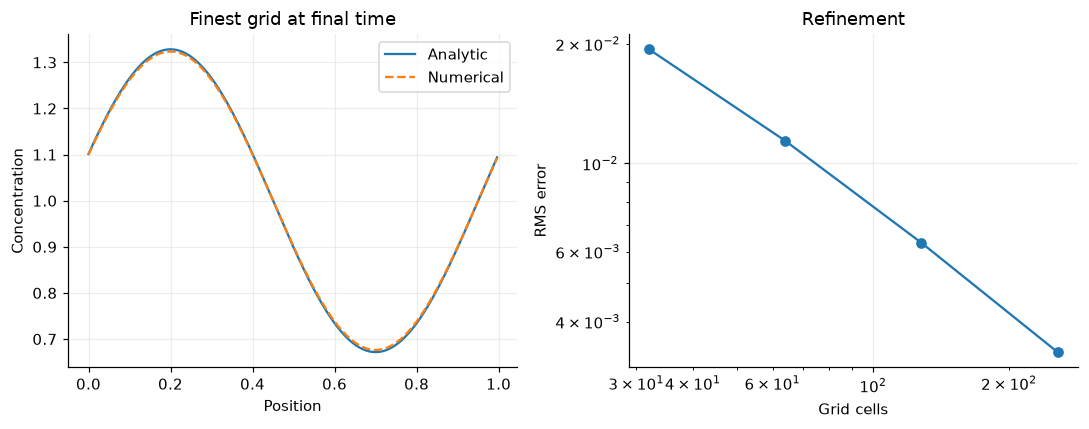

In [2]:
u=.4; D=.01; T=.5; grids=np.array([32,64,128,256]); rows=[]
for N in grids:
    dx=1/N; x=np.arange(N)*dx
    steps=int(np.ceil(T*(u/dx+2*D/dx**2)/.8)); h=T/steps
    nu=u*h/dx; r=D*h/dx**2
    y=1+.4*np.cos(2*np.pi*x); m=y.mean(); drift=0.
    for _ in range(steps):
        y=r*np.roll(y,-1)+(1-nu-2*r)*y+(nu+r)*np.roll(y,1)
        drift=max(drift,abs(y.mean()-m))
    exact=1+.4*np.exp(-4*np.pi**2*D*T)*np.cos(2*np.pi*(x-u*T))
    rms=np.sqrt(np.mean((y-exact)**2))
    rows.append((steps,rms,drift))
    print(f"N={N:3}, steps={steps:4}, RMS={rms:.4g}, mass drift={drift:.2g}")
rows=np.array(rows)
assert np.all(rows[:,2]<1e-12) and rows[-1,1]<.01 and np.all(np.diff(rows[:,1])<0)
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].plot(x,exact,label="Analytic"); ax[0].plot(x,y,"--",label="Numerical")
ax[0].set(xlabel="Position",ylabel="Concentration",title="Finest grid at final time"); ax[0].legend()
ax[1].loglog(grids,rows[:,1],"o-"); ax[1].set(xlabel="Grid cells",ylabel="RMS error",title="Refinement")
show(fig,"09-capstone")

## Worked exercise

**Why report the work as well as error?** Doubling resolution eventually requires roughly four times as many explicit steps for diffusion; there are also twice as many cells per step. The physical model was verified against an exact mathematical reference, but an actual pollutant study would need boundary, forcing and observational data.